### Лабораторна робота №4. Методи кластеризації

In [1]:
import pandas as pd

In [2]:
# 1. Відкрити та зчитати файл з даними.
file_path = "Input_Lab-2_3_4_WQ-R.csv"
data = pd.read_csv(file_path, delimiter=";")

In [3]:
# 2. Визначити та вивести кількість записів, а також кількість полів та їх тип у завантаженому наборі даних.
num_records = len(data)
num_fields = len(data.columns)
field_types = data.dtypes

print(f"Кількість записів: {num_records}")
print(f"Кількість полів: {num_fields}")
print("Типи полів:")
print(field_types)

Кількість записів: 1599
Кількість полів: 12
Типи полів:
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object


In [4]:
# 3. Видалити атрибут quality.
data = data.drop('quality', axis=1)

In [5]:
# 4. Вивести атрибути, що залишилися.
remaining_attributes = data.columns.tolist()
print("Атрибути, що залишилися:", remaining_attributes)

Атрибути, що залишилися: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']


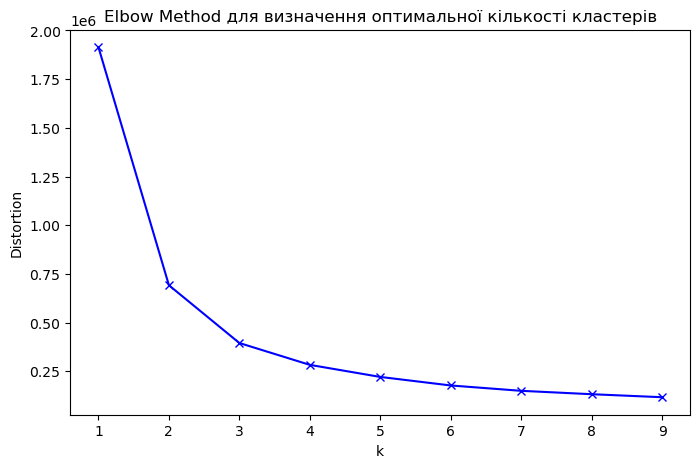

Координати центрів кластерів (KMeans):
[[7.88755187e+00 5.72365145e-01 2.75643154e-01 3.23236515e+00
  8.83983402e-02 2.61514523e+01 1.08506224e+02 9.96934730e-01
  3.28962656e+00 6.52033195e-01 1.00089212e+01]
 [8.46982759e+00 5.19519704e-01 2.68608374e-01 2.36102217e+00
  8.46059113e-02 8.99507389e+00 2.23928571e+01 9.96617512e-01
  3.31137931e+00 6.47216749e-01 1.05769294e+01]
 [8.28699634e+00 5.20503663e-01 2.72435897e-01 2.49706960e+00
  9.13095238e-02 2.15705128e+01 5.48882784e+01 9.96855769e-01
  3.32020147e+00 6.77106227e-01 1.03768010e+01]]


In [6]:
# 5. Використовуючи функцію KMeans бібліотеки scikit-learn, виконати розбиття набору даних на кластери з випадковою початковою ініціалізацією
# і вивести координати центрів кластерів. Оптимальну кількість кластерів визначити на основі початкового набору даних за допомогою elbow method.

# Використаємо elbow method для визначення оптимальної кількості кластерів
from sklearn.cluster import KMeans, AgglomerativeClustering

distortions = []
K = range(1, 10)
for k in K:
    kmeanModel = KMeans(n_init=10, n_clusters=k)
    kmeanModel.fit(data)
    distortions.append(kmeanModel.inertia_)

import matplotlib.pyplot as plt

# Відобразимо графік elbow method
plt.figure(figsize=(8, 5))
plt.plot(K, distortions, 'bx-')
plt.xlabel('k')
plt.ylabel('Distortion')
plt.title('Elbow Method для визначення оптимальної кількості кластерів')
plt.show()

# Беремо оптимальне k, наприклад, k=3
optimal_k = 3
kmeans = KMeans(n_init=10, n_clusters=optimal_k, init='random')
kmeans.fit(data)
cluster_centers_kmeans = kmeans.cluster_centers_
print("Координати центрів кластерів (KMeans):")
print(cluster_centers_kmeans)

In [7]:
# 6. Використовуючи функцію AgglomerativeClustering бібліотеки scikit-learn, виконати розбиття набору даних на кластери.
# Кількість кластерів обрати такою ж самою, як і в попередньому методі. Вивести координати центрів кластерів.

import numpy as np

agglomerative = AgglomerativeClustering(n_clusters=optimal_k)
agglomerative.fit(data)
cluster_centers_agglomerative = []
for label in range(optimal_k):
    cluster_centers_agglomerative.append(np.mean(data[agglomerative.labels_ == label], axis=0))
print("Координати центрів кластерів (AgglomerativeClustering):")
print(cluster_centers_agglomerative)

Координати центрів кластерів (AgglomerativeClustering):
[fixed acidity            8.170886
volatile acidity         0.530127
citric acid              0.256315
residual sugar           2.429325
chlorides                0.090435
free sulfur dioxide     19.587201
total sulfur dioxide    52.610408
density                  0.996791
pH                       3.334430
sulphates                0.665907
alcohol                 10.373277
dtype: float64, fixed acidity             7.980476
volatile acidity          0.557595
citric acid               0.288905
residual sugar            3.362857
chlorides                 0.089938
free sulfur dioxide      28.654762
total sulfur dioxide    111.342857
density                   0.996994
pH                        3.270714
sulphates                 0.659048
alcohol                   9.976587
dtype: float64, fixed acidity            8.580678
volatile acidity         0.516180
citric acid              0.280796
residual sugar           2.398378
chlorides       

In [8]:
# 7. Порівняти результати двох використаних методів кластеризації.

# Порівняння координат центрів кластерів
print("Координати центрів кластерів (KMeans):")
print(cluster_centers_kmeans)
print("\nКоординати центрів кластерів (AgglomerativeClustering):")
print(cluster_centers_agglomerative)

Координати центрів кластерів (KMeans):
[[7.88755187e+00 5.72365145e-01 2.75643154e-01 3.23236515e+00
  8.83983402e-02 2.61514523e+01 1.08506224e+02 9.96934730e-01
  3.28962656e+00 6.52033195e-01 1.00089212e+01]
 [8.46982759e+00 5.19519704e-01 2.68608374e-01 2.36102217e+00
  8.46059113e-02 8.99507389e+00 2.23928571e+01 9.96617512e-01
  3.31137931e+00 6.47216749e-01 1.05769294e+01]
 [8.28699634e+00 5.20503663e-01 2.72435897e-01 2.49706960e+00
  9.13095238e-02 2.15705128e+01 5.48882784e+01 9.96855769e-01
  3.32020147e+00 6.77106227e-01 1.03768010e+01]]

Координати центрів кластерів (AgglomerativeClustering):
[fixed acidity            8.170886
volatile acidity         0.530127
citric acid              0.256315
residual sugar           2.429325
chlorides                0.090435
free sulfur dioxide     19.587201
total sulfur dioxide    52.610408
density                  0.996791
pH                       3.334430
sulphates                0.665907
alcohol                 10.373277
dtype: float

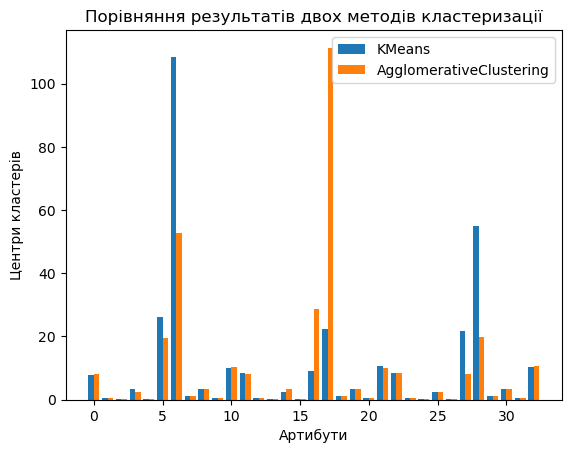

In [9]:
import numpy as np

cluster_centers_agglomerative_values = list(map(lambda x: x.values.tolist(), cluster_centers_agglomerative))
cluster_centers_agglomerative_values = np.array(cluster_centers_agglomerative_values).reshape(-1)

X_axis = np.arange(len(cluster_centers_kmeans.reshape(-1))) 
plt.bar(X_axis - 0.2, cluster_centers_kmeans.reshape(-1), 0.4, label = 'KMeans')
plt.bar(X_axis + 0.2, cluster_centers_agglomerative_values, 0.4, label = 'AgglomerativeClustering')

plt.xlabel("Артибути")
plt.ylabel("Центри кластерів")
plt.title("Порівняння результатів двох методів кластеризації")
plt.legend() 
plt.show() 